In [1]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize
from pathlib import Path
import mne
import csv
import json
import sys

print(__doc__)

PROJECT_ROOT = Path.cwd().resolve()

# Nach oben gehen, bis das Datenverzeichnis gefunden wird
while not (PROJECT_ROOT / "data" / "raw" / "ds005363-download").is_dir():
    if PROJECT_ROOT == PROJECT_ROOT.parent:
        raise FileNotFoundError("Projektverzeichnis nicht gefunden.")

    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_ROOT = PROJECT_ROOT / "data" / "raw" / "ds005363-download"

BUNDLE_DIR = PROJECT_ROOT / "notebooks" / "BunDLe-Net"
if str(BUNDLE_DIR) not in sys.path:
    sys.path.insert(0, str(BUNDLE_DIR))

print("Arbeitsverzeichnis:", Path.cwd())
print("Datenverzeichnis:", DATA_ROOT)

def first_matching(directory: Path, pattern: str) -> Path:
    matches = sorted(directory.glob(pattern))
    if not matches:
        raise FileNotFoundError(f"Keine Datei mit Muster {pattern!r} in {directory}")
    return matches[0]

def read_tsv(path: Path) -> list[dict[str, str]]:
    """Liest eine TSV-Datei robust gegen ein UTF-8-BOM ein."""

    with path.open("r", encoding="utf-8-sig", newline="") as file:
        return list(csv.DictReader(file, delimiter="\t"))
    
def subject_directory(data_root: Path, subject: str) -> Path:
    subject_label = subject if subject.startswith("sub-") else f"sub-{subject}"
    directory = data_root / subject_label / "ses-01" / "eeg"
    if not directory.is_dir():
        raise FileNotFoundError(f"EEG-Verzeichnis nicht gefunden: {directory}")
    return directory

subjects_dir = subject_directory(DATA_ROOT, "101")

def read_data(subject: str, duration: float, data_root: Path, output_root: Path): 
    eeg_dir = subject_directory(data_root, subject)

    vhdr_path = first_matching(eeg_dir, "*_eeg.vhdr")
    json_path = first_matching(eeg_dir, "*_eeg.json")
    channels_path = first_matching(eeg_dir, "*_channels.tsv")
    events_path = first_matching(eeg_dir, "*_events.tsv")

    with json_path.open("r", encoding="utf-8") as file:
        metadata = json.load(file)
    channels = read_tsv(channels_path)
    events = read_tsv(events_path)

    print(f"Lese BrainVision-Aufnahme ein: {vhdr_path}")
    raw = mne.io.read_raw_brainvision(vhdr_path, preload=True, verbose="ERROR")
    eeg_picks = mne.pick_types(raw.info, eeg=True, exclude=[])
    if len(eeg_picks) == 0:
        raise RuntimeError("Die Aufnahme enthält keine als EEG markierten Kanäle.")

    return raw, channels, events

Automatically created module for IPython interactive environment
Arbeitsverzeichnis: /home/bened/bachelor-thesis/notebooks/BunDLe-Net/notebooks
Datenverzeichnis: /home/bened/bachelor-thesis/data/raw/ds005363-download


Lese BrainVision-Aufnahme ein: /home/bened/bachelor-thesis/data/raw/ds005363-download/sub-101/ses-01/eeg/sub-101_ses-01_task-objrecog_eeg.vhdr


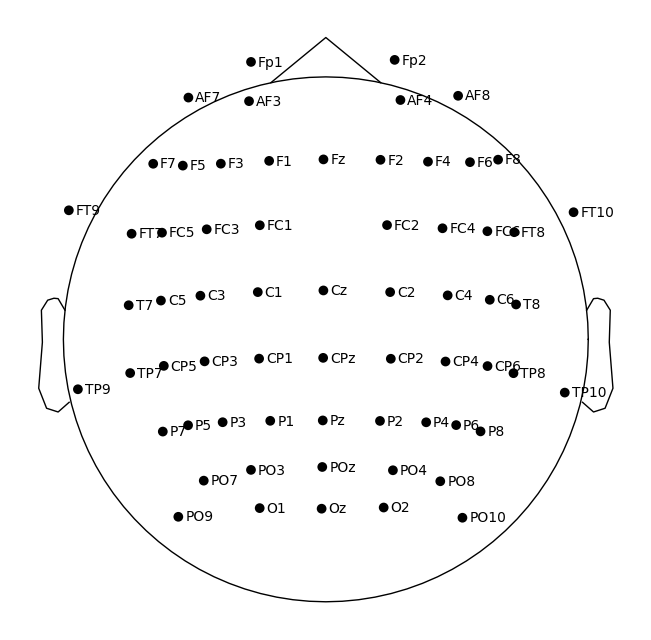

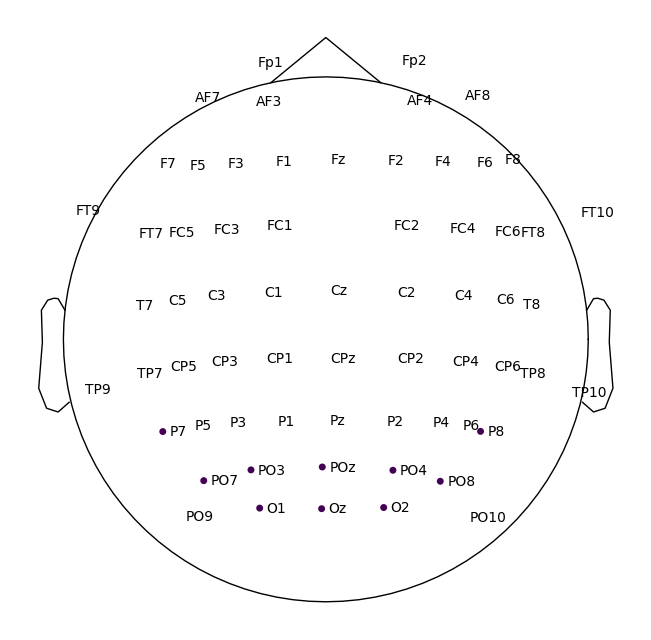

In [2]:
try:
    raw, channels, events = read_data(
        subject="101",
        duration=60.0,
        data_root=DATA_ROOT,
        output_root=PROJECT_ROOT / "results",
    )

except FileNotFoundError as exc:
    raise SystemExit(f"Datei nicht verfügbar: {exc}") from exc
except RuntimeError as exc:
    raise SystemExit(f"Analyse konnte nicht durchgeführt werden: {exc}") from exc

raw.set_montage("standard_1020")
raw.plot_sensors(show_names=True)

auswahl = ["O1", "Oz", "O2", "PO7", "PO3", "POz", "PO4", "PO8", "P7", "P8"]  # Beispiel

fig = mne.viz.plot_sensors(
    raw.info,
    show_names=True,
    ch_groups=[[raw.ch_names.index(ch) for ch in auswahl]],
    linewidth=0,
)

In [3]:
raw.load_data()
raw.filter(l_freq=0.5, h_freq=None)


Filtering raw data in 1 contiguous segment
Setting up high-pass filter at 0.5 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal highpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 0.50
- Lower transition bandwidth: 0.50 Hz (-6 dB cutoff frequency: 0.25 Hz)
- Filter length: 6601 samples (6.601 s)



<RawBrainVision | sub-101_ses-01_task-objrecog_eeg.eeg, 64 x 4178520 (4178.5 s), ~1.99 GiB, data loaded>

In [4]:
events_arr, event_dict = mne.events_from_annotations(raw)

categories = {"face": range(1, 17), "animal": range(17, 33),
              "place": range(33, 49), "object": range(49, 65)}

event_id = {f"{name}/S{n}": event_dict[f"Stimulus/S{n:>3}"]
            for name, nums in categories.items() for n in nums}

epochs = mne.Epochs(raw, events_arr, event_id=event_id,
                    tmin=-0.3, tmax=0.7, baseline=(None, 0),
                    preload=True, event_repeated="drop")

epochs_face_obj = epochs[["face", "object"]]
epochs_face_obj

Used Annotations descriptions: [np.str_('Comment/actiCAP Data On'), np.str_('Stimulus/S  1'), np.str_('Stimulus/S  2'), np.str_('Stimulus/S  3'), np.str_('Stimulus/S  4'), np.str_('Stimulus/S  5'), np.str_('Stimulus/S  6'), np.str_('Stimulus/S  7'), np.str_('Stimulus/S  8'), np.str_('Stimulus/S  9'), np.str_('Stimulus/S 10'), np.str_('Stimulus/S 11'), np.str_('Stimulus/S 12'), np.str_('Stimulus/S 13'), np.str_('Stimulus/S 14'), np.str_('Stimulus/S 15'), np.str_('Stimulus/S 16'), np.str_('Stimulus/S 17'), np.str_('Stimulus/S 18'), np.str_('Stimulus/S 19'), np.str_('Stimulus/S 20'), np.str_('Stimulus/S 21'), np.str_('Stimulus/S 22'), np.str_('Stimulus/S 23'), np.str_('Stimulus/S 24'), np.str_('Stimulus/S 25'), np.str_('Stimulus/S 26'), np.str_('Stimulus/S 27'), np.str_('Stimulus/S 28'), np.str_('Stimulus/S 29'), np.str_('Stimulus/S 30'), np.str_('Stimulus/S 31'), np.str_('Stimulus/S 32'), np.str_('Stimulus/S 33'), np.str_('Stimulus/S 34'), np.str_('Stimulus/S 35'), np.str_('Stimulus/S 36

<Epochs | 1024 events (all good), -0.3 – 0.7 s (baseline -0.3 – 0 s), ~500.6 MiB, data loaded,
 'face/S1': 32
 'face/S2': 32
 'face/S3': 32
 'face/S4': 32
 'face/S5': 32
 'face/S6': 32
 'face/S7': 32
 'face/S8': 32
 'face/S9': 32
 'face/S10': 32
 and 22 more events ...>

Estimating rejection dictionary for eeg
0 bad epochs dropped


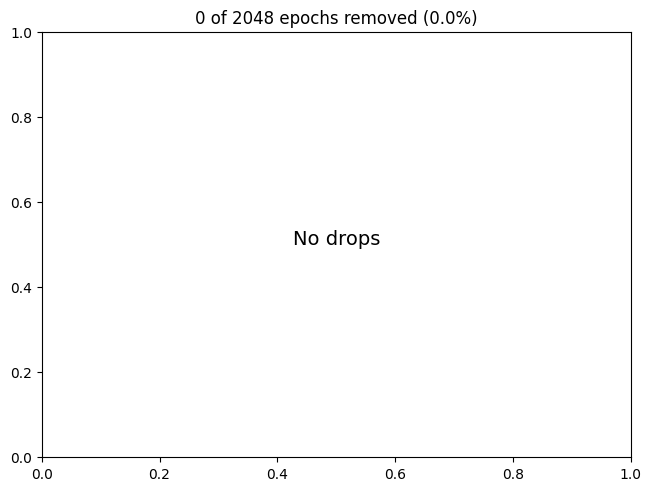

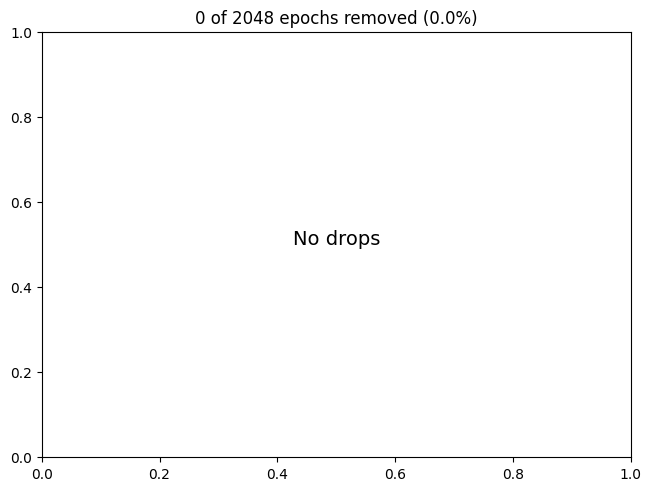

In [5]:
import autoreject

epochs.resample(250)                    

rng = np.random.default_rng(11)
fit_idx = rng.choice(len(epochs), 200, replace=False)   

"""ar = autoreject.AutoReject(n_interpolate=[1, 4], random_state=11,
                           n_jobs=-1, verbose=True)     
ar.fit(epochs[fit_idx])
epochs_ar, reject_log = ar.transform(epochs, return_log=True)"""

reject = autoreject.get_rejection_threshold(epochs)   # z. B. {'eeg': 1.2e-4}
epochs_clean = epochs.copy().drop_bad(reject=reject)
epochs_clean
epochs_clean.plot_drop_log()

In [6]:
n_train = int(0.8 * len(epochs_clean))
idx = rng.permutation(len(epochs_clean))

epochs_train = epochs_clean[idx[:n_train]]
epochs_test = epochs_clean[idx[n_train:]]

X_train = epochs_train.get_data()
X_test = epochs_test.get_data()

scaler = mne.decoding.Scaler(scalings="mean")
X_train = scaler.fit_transform(X_train)
X_test=scaler.transform(X_test)

print(X_train.shape, X_test.shape) 

(1638, 64, 250) (410, 64, 250)


In [7]:
def make_B(ep):
    codes = ep.events[:, 2]
    cat = (codes - 1) // 16 + 1            # 1=face, 2=animal, 3=place, 4=object
    B = np.zeros((len(ep), len(ep.times)), dtype=int)
    B[:, ep.times >= 0] = cat[:, None]
    return B

B_train = make_B(epochs_train)    # (1638, 250)
B_test  = make_B(epochs_test)     # (410, 250)

print(B_test)
print(B_train)
print(epochs.events[:,2])


[[0 0 0 ... 3 3 3]
 [0 0 0 ... 3 3 3]
 [0 0 0 ... 3 3 3]
 ...
 [0 0 0 ... 2 2 2]
 [0 0 0 ... 4 4 4]
 [0 0 0 ... 1 1 1]]
[[0 0 0 ... 2 2 2]
 [0 0 0 ... 2 2 2]
 [0 0 0 ... 2 2 2]
 ...
 [0 0 0 ... 2 2 2]
 [0 0 0 ... 3 3 3]
 [0 0 0 ... 1 1 1]]
[63 11 31 ... 11 62 40]


In [8]:
import tensorflow as tf
from functions import BunDLeTrainer, BunDLeNet

NUMBER_OF_IMAGES_PER_CATEGORY = 16
LABEL_BEFORE_IMAGE_ONSET = 0

model = BunDLeNet(3)
optimizer = tf.keras.optimizers.Adam(learning_rate=0.001)
trainer = BunDLeTrainer(model, optimizer)

win = 25                                   # 25 Samples = 100 ms bei 250 Hz
batch_size = 1024
gamma = 0.9
all_losses = []

def create_labels_for_epochs(epochs):
    """
    Gibt eine Matrix mit der Form (Anzahl Epochs, Anzahl Zeitpunkte) zurück.
    Vor dem Bildbeginn steht 0, ab dem Bildbeginn die Kategorie:
    1 = Gesicht, 2 = Tier, 3 = Ort, 4 = Objekt.
    """
    image_numbers = epochs.events[:, 2]

    category_per_epoch = (image_numbers - 1) // NUMBER_OF_IMAGES_PER_CATEGORY + 1

    number_of_epochs = len(epochs)
    number_of_time_points = len(epochs.times)
    labels = np.full(
        (number_of_epochs, number_of_time_points),
        LABEL_BEFORE_IMAGE_ONSET,
        dtype=int,
    )

    time_points_after_image_onset = epochs.times >= 0
    for epoch_number in range(number_of_epochs):
        labels[epoch_number, time_points_after_image_onset] = category_per_epoch[epoch_number]

    return labels


I0000 00:00:1793982234.444513   58202 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793982234.473370   58202 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793982235.767696   58202 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
W0000 00:00:1793982236.430513   58202 gpu_device.cc:2459] TensorFlow was not built with CUDA kernel binaries compatible with compute c

In [9]:
def list_all_window_pairs(number_of_epochs, number_of_time_points, window_length):
    """
    Jedes Fensterpaar ist eindeutig durch zwei Zahlen beschrieben:
    aus welcher Epoch es stammt und an welchem Zeitpunkt das erste Fenster beginnt.
    Das zweite Fenster ist um einen Zeitpunkt verschoben, deshalb braucht ein Paar
    window_length + 1 Zeitpunkte. Paare über Epoch-Grenzen hinweg gibt es nicht.
    """
    number_of_start_points_per_epoch = number_of_time_points - window_length

    epoch_numbers = []
    start_time_points = []
    for epoch_number in range(number_of_epochs):
        for start_time_point in range(number_of_start_points_per_epoch):
            epoch_numbers.append(epoch_number)
            start_time_points.append(start_time_point)

    return np.array(epoch_numbers), np.array(start_time_points)


In [10]:
def build_training_batch(eeg_data, labels, epoch_numbers, start_time_points, window_length):
    """
    eeg_data:  Form (Anzahl Epochs, Anzahl Kanäle, Anzahl Zeitpunkte)
    labels:    Form (Anzahl Epochs, Anzahl Zeitpunkte)

    Rückgabe wie bei prep_data:
    window_pairs:  Form (Anzahl Paare, 2, window_length, Anzahl Kanäle)
    target_labels: Form (Anzahl Paare,)
    """
    window_pairs = []
    target_labels = []

    for epoch_number, start_time_point in zip(epoch_numbers, start_time_points):
        one_epoch = eeg_data[epoch_number].T          # Form (Zeitpunkte, Kanäle)

        first_window = one_epoch[start_time_point : start_time_point + window_length]
        second_window = one_epoch[start_time_point + 1 : start_time_point + window_length + 1]

        window_pairs.append(np.stack([first_window, second_window]))

        last_time_point_of_second_window = start_time_point + window_length
        target_labels.append(labels[epoch_number, last_time_point_of_second_window])

    return np.array(window_pairs, dtype=np.float32), np.array(target_labels)


In [11]:
window_length = 25            # 25 Zeitpunkte = 100 Millisekunden bei 250 Hertz

labels_train = create_labels_for_epochs(epochs_train)    # Form (1638, 250)
labels_test = create_labels_for_epochs(epochs_test)      # Form (410, 250)

number_of_epochs, number_of_channels, number_of_time_points = X_train.shape
epoch_numbers, start_time_points = list_all_window_pairs(
    number_of_epochs, number_of_time_points, window_length
)

random_generator = np.random.default_rng(11)
shuffled_order = random_generator.permutation(len(epoch_numbers))

for batch_start in range(0, len(shuffled_order), batch_size):
    selected_pairs = shuffled_order[batch_start : batch_start + batch_size]

    window_pairs, target_labels = build_training_batch(
        X_train,
        labels_train,
        epoch_numbers[selected_pairs],
        start_time_points[selected_pairs],
        window_length,
    )

    markov_loss, behaviour_loss, total_loss = trainer.train_step(
        tf.convert_to_tensor(window_pairs, dtype=tf.float32),
        tf.convert_to_tensor(target_labels, dtype=tf.int64),
        gamma=gamma,
    )
    all_losses.append([float(markov_loss), float(behaviour_loss), float(total_loss)])


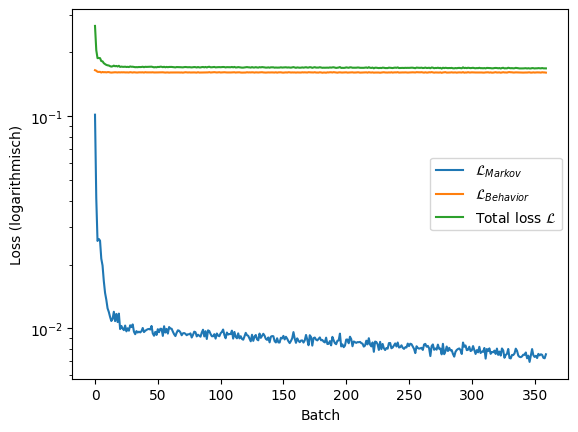

In [12]:
loss_history = np.array(all_losses)      # Form (Anzahl Batches, 3)

loss_names = [
    r"$\mathcal{L}_{Markov}$",
    r"$\mathcal{L}_{Behavior}$",
    r"Total loss $\mathcal{L}$",
]

plt.figure()
for column_number, loss_name in enumerate(loss_names):
    plt.semilogy(loss_history[:, column_number], label=loss_name)
plt.xlabel("Batch")
plt.ylabel("Loss (logarithmisch)")
plt.legend()
plt.show()